In [4]:
# Import libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
# Load Netflix dataset
df = pd.read_csv("netflix_titles.csv")
print(df.head())

  show_id     type                  title         director  \
0      s1    Movie   Dick Johnson Is Dead  Kirsten Johnson   
1      s2  TV Show          Blood & Water              NaN   
2      s3  TV Show              Ganglands  Julien Leclercq   
3      s4  TV Show  Jailbirds New Orleans              NaN   
4      s5  TV Show           Kota Factory              NaN   

                                                cast        country  \
0                                                NaN  United States   
1  Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...   South Africa   
2  Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...            NaN   
3                                                NaN            NaN   
4  Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...          India   

           date_added  release_year rating   duration  \
0  September 25, 2021          2020  PG-13     90 min   
1  September 24, 2021          2021  TV-MA  2 Seasons   
2  September 24, 2021        

In [6]:
df.info()
print(df.shape)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB
(8807, 12)


In [7]:
print(df.describe(include="all"))
# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

       show_id   type                 title       director  \
count     8807   8807                  8807           6173   
unique    8807      2                  8807           4528   
top         s1  Movie  Dick Johnson Is Dead  Rajiv Chilaka   
freq         1   6131                     1             19   
mean       NaN    NaN                   NaN            NaN   
std        NaN    NaN                   NaN            NaN   
min        NaN    NaN                   NaN            NaN   
25%        NaN    NaN                   NaN            NaN   
50%        NaN    NaN                   NaN            NaN   
75%        NaN    NaN                   NaN            NaN   
max        NaN    NaN                   NaN            NaN   

                      cast        country       date_added  release_year  \
count                 7982           7976             8797   8807.000000   
unique                7692            748             1767           NaN   
top     David Attenborough 

type
Movie      6131
TV Show    2676
Name: count, dtype: int64


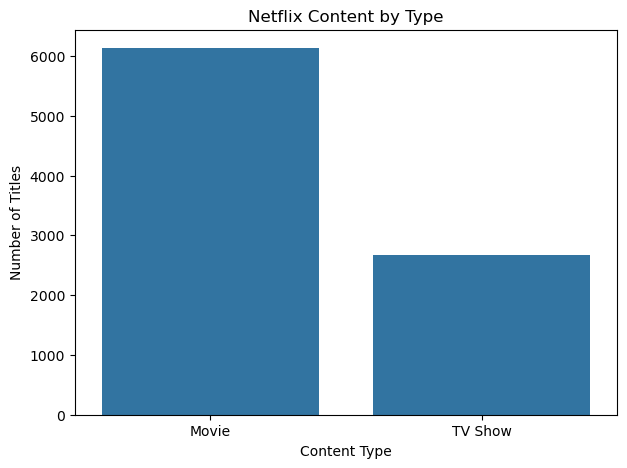

In [8]:
# 3. CONTENT TYPE ANALYSIS
print(df["type"].value_counts())

plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="type")
plt.title("Netflix Content by Type")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")
plt.show()

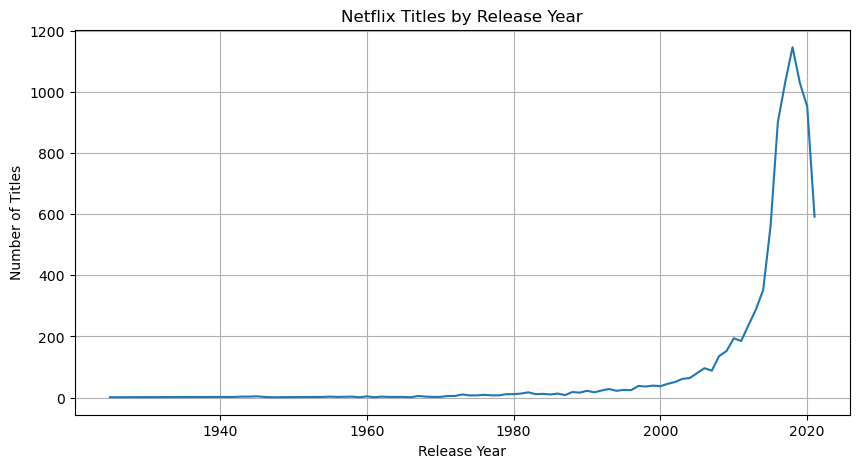

In [9]:
# 4. TREND BY RELEASE YEAR
year_count = df["release_year"].value_counts().sort_index()

plt.figure(figsize=(10, 5))
plt.plot(year_count.index, year_count.values)
plt.title("Netflix Titles by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.grid(True)
plt.show()

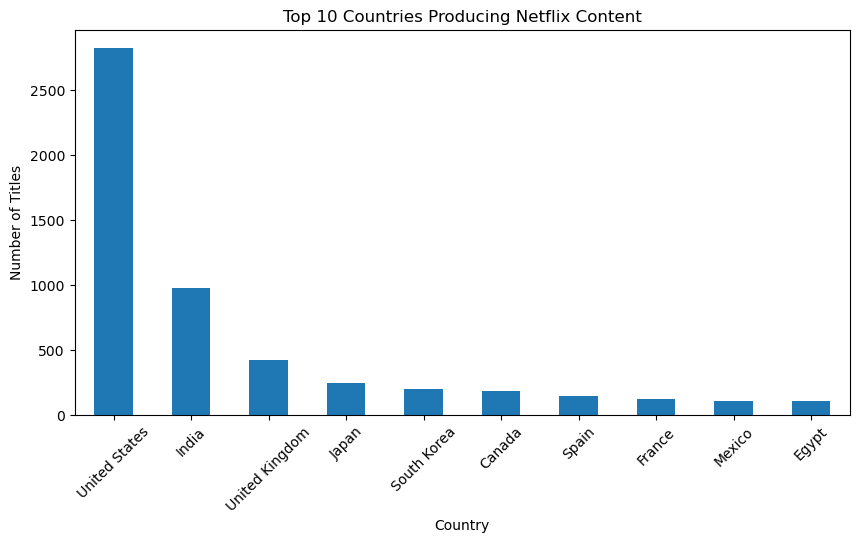

In [10]:
# TOP 10 COUNTRIES
top_countries = df["country"].value_counts().head(10)

plt.figure(figsize=(10, 5))
top_countries.plot(kind="bar")
plt.title("Top 10 Countries Producing Netflix Content")
plt.xlabel("Country")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)
plt.show()

              release_year
release_year           1.0


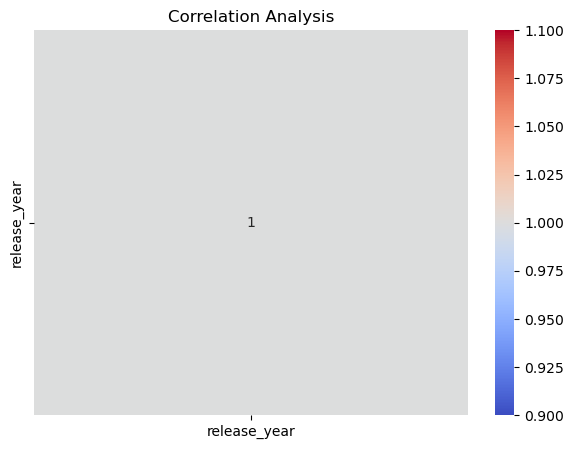

In [11]:
#CORRELATION ANALYSIS
# Select numerical columns
numeric_df = df.select_dtypes(include=["int64", "float64"])
print(numeric_df.corr())

# Correlation heatmap
plt.figure(figsize=(7, 5))
sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm")
plt.title("Correlation Analysis")
plt.show()

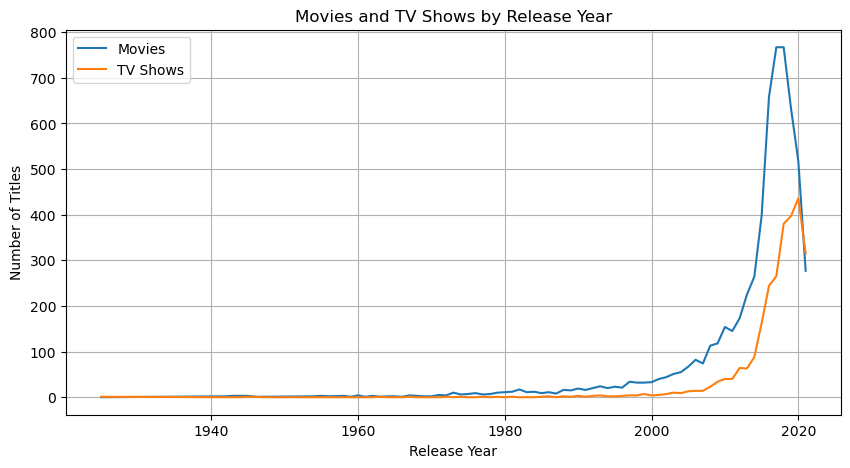

In [12]:
# MOVIES VS TV SHOWS BY YEAR
content_year = df.groupby(
    ["release_year", "type"]).size().unstack(fill_value=0)
plt.figure(figsize=(10, 5))
if "Movie" in content_year.columns:
    plt.plot(
        content_year.index,
        content_year["Movie"],
        label="Movies" )

if "TV Show" in content_year.columns:
    plt.plot(
        content_year.index,
        content_year["TV Show"],
        label="TV Shows")

plt.title("Movies and TV Shows by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.legend()
plt.grid(True)
plt.show()